# 05 · The PIC's Gaussian band-pass envelope (`envbp`), simulated on recorded echoes

**No board needed.** This notebook re-runs, in Python, exactly what the PIC32AK does for `envbp` (pic ≥ 1.1.6,
`firmware/pic32/pe_ext.c: pe_envbp`) on raw RF captures recorded with the board, and compares the result with the
envelopes the PIC itself returned in the same session.

Data: `docs/bench/2026-11-22-datasheet-ext/envbp.npz` — board 3 (minus v1.1), rp 1.1.9 / pic 1.1.6 (proto 15),
3.3 MHz single-element transducer (datasheet Annex A), gain ×3.2 (`gain 0 1 0`), recorded 2026-11-22 15:54 by
`campaign.py envbp`. It holds:

* `pe_ref` — 16 raw `pe` captures (4095 samples, 12-bit, dt = 40.2 ns ≈ 24.9 Msps): **the input of the simulation**;
* `bp_f<fc>_b<bw>_s<shots>` — what the PIC returned for `envbp 8 <shots> 25 <fc> <bw>` (5 runs each);
* `env_s1`, `env_s16` — the older rectify-and-average `env 8` for comparison.

The PIC computes its envelopes on its *own* shots (it does not send the RF), so the simulated and measured envelopes
come from different pulses of the same session: the comparison is statistical (peak, floor, dB), not sample by sample.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parents[1]                       # repo root (notebook lives in python/notebooks)
z = np.load(ROOT / "docs/bench/2026-11-22-datasheet-ext/envbp.npz")
meta = json.loads(str(z["meta"])); print(meta)
rf = z["pe_ref"].astype(float)                               # (16 shots, 4095 samples), 12-bit LSB
dt = float(z["pe_dt_ns"]) * 1e-9                              # sample period of the raw capture
t = np.arange(rf.shape[1]) * dt * 1e6                         # µs after the pulse
print(f"{rf.shape[0]} shots x {rf.shape[1]} samples, dt = {dt*1e9:.2f} ns ({1e-6/dt:.2f} Msps), "
      f"range {rf.min():.0f}..{rf.max():.0f} LSB")

{'rp': '1.1.9', 'pic': '1.1.6', 'proto': 15, 'date': '2026-11-22 15:54', 'board': 'minus v1.1 (board 3), RP unique id 7D4466C63B374C98', 'transducer': '3.3 MHz single element (Annex A)'}
16 shots x 4095 samples, dt = 40.20 ns (24.88 Msps), range 0..4068 LSB


/home/kelu/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## 1 · What the PIC computes

For `envbp <dec> <shots> <in> <fc_khz> <bw_khz>` the PIC:

1. captures 4095 samples (same capture as `pe`), and measures the real sample period `dt` from Timer1;
2. builds a **complex Gaussian filter** (a Gabor kernel): $h[k] = g[k]\,e^{\,j\omega k}$ with
   $g[k]=\exp\!\left(-\tfrac12 (k\,dt/\sigma_t)^2\right)$, $\omega = 2\pi f_c\,dt$,
   $\sigma_f = \mathrm{FWHM}/2.3548$, $\sigma_t = 1/(2\pi\sigma_f)$, truncated at ±3 σ_t (max ±32 taps).
   Its spectrum is a Gaussian centred on +f_c only, so the output is already the **analytic signal** of the
   band-passed RF: band-pass and Hilbert transform in one FIR, no FFT, no 4095-point complex buffer
   (the PIC has 16 KB of RAM to spare);
3. removes the capture mean, and evaluates the filter **only at the centre of every block of `dec` samples**
   (dec 8 → 511 outputs, one every 322 ns) — 8× less work than filtering every sample;
4. takes the magnitude, scales it by 2/Σg (amplitude of a real sine at f_c) and stores it in 1/16 LSB;
5. averages over `shots` captures (integer sum / count) and returns the 511 values (the library divides by 16).

The function below is a line-by-line port of `pe_envbp` (same float formulas, same rounding).

In [2]:
def pic_envbp(x, dt, dec=8, fc_khz=3300, bw_khz=2500, BP_MAXHALF=32):
    # Port of firmware/pic32/pe_ext.c pe_envbp() for one shot. Returns (envelope in LSB, taps c, taps s, half).
    sig_f = bw_khz * 1e3 / 2.3548
    sig_t = 1.0 / (2 * np.pi * sig_f)
    half = int(3.0 * sig_t / dt + 0.5)
    half = min(max(half, 1), BP_MAXHALF)
    k = np.arange(-half, half + 1)
    g = np.exp(-0.5 * (k * dt / sig_t) ** 2)
    w = 2 * np.pi * fc_khz * 1e3 * dt
    c, s = g * np.cos(w * k), g * np.sin(w * k)
    scale = 2.0 * 16.0 / g.sum()                    # 2: one side of a real sine; 16: 1/16 LSB units
    x = x - x.mean()
    n = len(x) // dec
    out = np.empty(n)
    for j in range(n):
        i = j * dec + dec // 2 + k                  # block centre +- half
        m = (i >= 0) & (i < len(x))
        re, im = (c[m] * x[i[m]]).sum(), (s[m] * x[i[m]]).sum()
        out[j] = np.floor(np.hypot(re, im) * scale + 0.5)   # (uint32_t)(a + 0.5)
    return out / 16.0, c, s, half

def pic_envbp_avg(shots, dt, dec=8, **kw):
    # Shot averaging as on the PIC: integer sum of 1/16-LSB values, rounded division by the count.
    acc = sum(pic_envbp(x, dt, dec, **kw)[0] * 16 for x in shots)
    n = len(shots)
    return np.floor((acc + n // 2) / n) / 16.0

env1, c, s, half = pic_envbp(rf[0], dt)
dec = 8
te = (np.arange(len(env1)) * dec + dec // 2) * dt * 1e6     # time of each output (block centre)
print(f"fc 3.3 MHz, FWHM 2.5 MHz: sigma_t = {1/(2*np.pi*2.5e6/2.3548)*1e9:.1f} ns, "
      f"{2*half+1} taps (+-{half}), {len(env1)} outputs, one every {dec*dt*1e9:.0f} ns")

fc 3.3 MHz, FWHM 2.5 MHz: sigma_t = 149.9 ns, 23 taps (+-11), 511 outputs, one every 322 ns


## 2 · The filter: taps and frequency response

Left: the 23 real/imaginary taps (a 3.3 MHz cosine/sine under a Gaussian window). Right: the filter's response,
on top of the mean spectrum of the 16 recorded shots. The transducer's echo energy sits around 3.3 MHz; everything
outside (DC drift, the 0.49 / 2.72 MHz interference, the period-4 pattern at fs/4 = 6.2 MHz and fs/2 = 12.4 MHz,
wideband noise) is attenuated — this is where the floor drops.

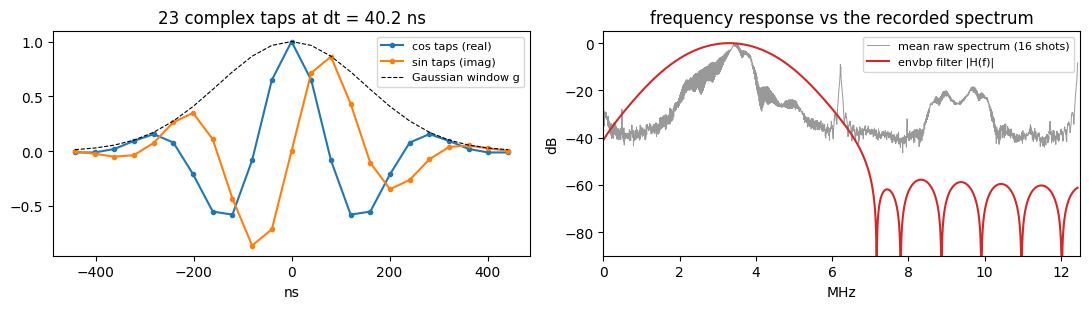

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
k = np.arange(-half, half + 1)
ax[0].plot(k * dt * 1e9, c, "o-", ms=3, label="cos taps (real)")
ax[0].plot(k * dt * 1e9, s, "o-", ms=3, label="sin taps (imag)")
ax[0].plot(k * dt * 1e9, np.hypot(c, s), "k--", lw=0.8, label="Gaussian window g")
ax[0].set_xlabel("ns"); ax[0].set_title(f"{2*half+1} complex taps at dt = {dt*1e9:.1f} ns"); ax[0].legend(fontsize=8)

f = np.fft.rfftfreq(rf.shape[1], dt)
S = np.mean([np.abs(np.fft.rfft((y - y.mean()) * np.hanning(len(y)))) for y in rf], axis=0)
H = np.abs(np.array([np.sum((c + 1j * s) * np.exp(-2j * np.pi * fi * k * dt)) for fi in f])) / np.hypot(c, s).sum()
ax[1].plot(f / 1e6, 20 * np.log10(S / S.max()), color="0.6", lw=0.7, label="mean raw spectrum (16 shots)")
ax[1].plot(f / 1e6, 20 * np.log10(np.maximum(H, 1e-6)), "C3", lw=1.5, label="envbp filter |H(f)|")
ax[1].set_ylim(-90, 5); ax[1].set_xlim(0, 12.5); ax[1].set_xlabel("MHz"); ax[1].set_ylabel("dB")
ax[1].set_title("frequency response vs the recorded spectrum"); ax[1].legend(fontsize=8)
fig.tight_layout()

## 3 · Raw RF (background) and the PIC's filtered envelope (foreground)

One recorded shot. Grey = the raw RF minus its mean, as it comes out of the ADC; red = the simulated `envbp`
envelope (±, so that it wraps the RF). The first echo (43 µs ≈ 33 mm) and the second (86 µs) stand out; the
transmit pulse saturates the front end during the first ~10 µs.

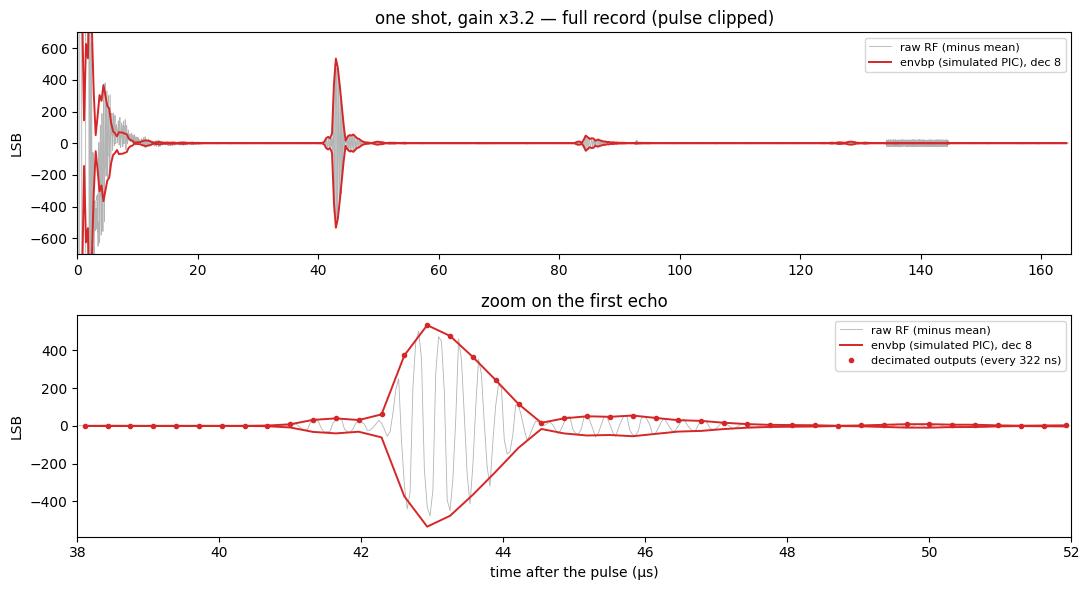

In [4]:
x0 = rf[0] - rf[0].mean()
fig, ax = plt.subplots(2, 1, figsize=(11, 6))
for a, (lo, hi) in zip(ax, ((0, 165), (38, 52))):
    m = (t >= lo) & (t <= hi); me = (te >= lo) & (te <= hi)
    a.plot(t[m], x0[m], color="0.7", lw=0.6, label="raw RF (minus mean)")
    a.plot(te[me], env1[me], "C3", lw=1.4, label="envbp (simulated PIC), dec 8")
    a.plot(te[me], -env1[me], "C3", lw=1.4)
    if hi - lo < 30:
        a.plot(te[me], env1[me], "C3o", ms=3, label="decimated outputs (every 322 ns)")
    a.set_xlim(lo, hi); a.set_ylabel("LSB"); a.legend(fontsize=8, loc="upper right")
ax[0].set_ylim(-700, 700); ax[0].set_title("one shot, gain x3.2 — full record (pulse clipped)")
ax[1].set_title("zoom on the first echo"); ax[1].set_xlabel("time after the pulse (µs)")
fig.tight_layout()

## 4 · Same overlay in dB: where the dynamic range comes from

Both traces on a dB scale (re 1 LSB). Background: the raw rectified RF |x − mean| (what `env`-style detectors see).
Foreground: the `envbp` envelope. The echo peaks stay where they are; the **floor between the echoes drops** because
the out-of-band noise is filtered away. Metric (same as datasheet §5): first-echo peak (38–52 µs) / rms of the envelope
in the echo-free 55–78 µs window.

Note the 10 µs block at ~135–145 µs in the raw trace: an out-of-band burst (a fixed-pattern disturbance during the
capture, not an echo) that is ~25 dB above the floor in the raw data and disappears completely after the filter.

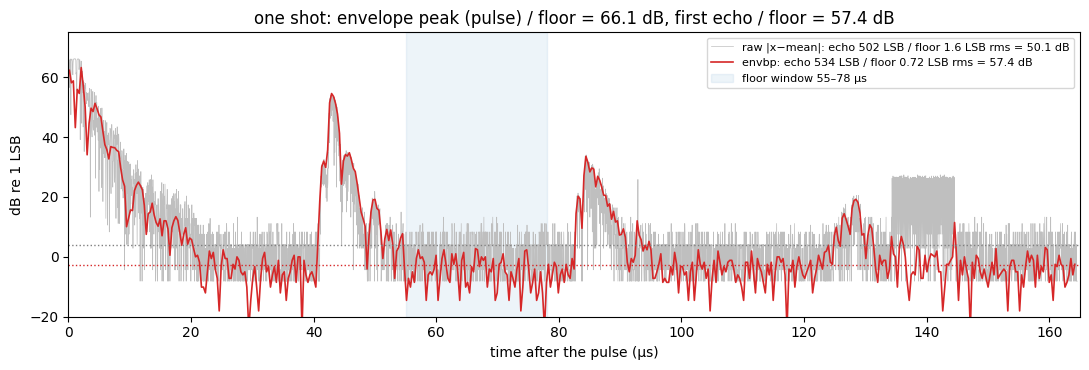

In [5]:
q, e1 = (te > 55) & (te < 78), (te > 38) & (te < 52)
qr, e1r = (t > 55) & (t < 78), (t > 38) & (t < 52)
def db(v): return 20 * np.log10(np.maximum(v, 1e-2))
def pk_floor(env, qq, ee): return env[ee].max(), np.sqrt((env[qq] ** 2).mean())

raw_rect = np.abs(x0)
p_r, f_r = pk_floor(raw_rect, qr, e1r)
p_b, f_b = pk_floor(env1, q, e1)
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(t, db(raw_rect), color="0.75", lw=0.5, label=f"raw |x−mean|: echo {p_r:.0f} LSB / floor {f_r:.1f} LSB rms = {db(p_r/f_r):.1f} dB")
ax.plot(te, db(env1), "C3", lw=1.2, label=f"envbp: echo {p_b:.0f} LSB / floor {f_b:.2f} LSB rms = {db(p_b/f_b):.1f} dB")
ax.axvspan(55, 78, color="C0", alpha=0.08, label="floor window 55–78 µs")
ax.axhline(db(f_r), color="0.5", ls=":", lw=1); ax.axhline(db(f_b), color="C3", ls=":", lw=1)
ax.set_xlim(0, 165); ax.set_ylim(-20, 75); ax.set_xlabel("time after the pulse (µs)"); ax.set_ylabel("dB re 1 LSB")
ax.set_title(f"one shot: envelope peak (pulse) / floor = {db(env1.max()/f_b):.1f} dB, first echo / floor = {db(p_b/f_b):.1f} dB")
ax.legend(fontsize=8, loc="upper right"); fig.tight_layout()

## 5 · All 16 shots: raw vs filtered, as an M-mode-like stack

Each row is one recorded shot (time runs left to right), in dB re 1 LSB, same colour scale for both panels.

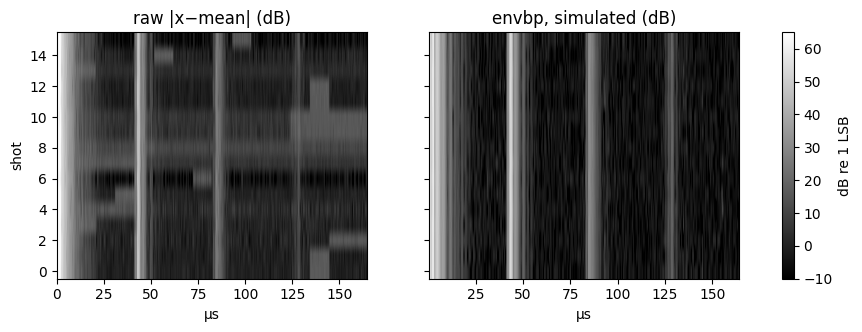

In [6]:
E = np.array([pic_envbp(y, dt)[0] for y in rf])
R = np.abs(rf - rf.mean(1, keepdims=True))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
kw = dict(aspect="auto", origin="lower", vmin=-10, vmax=65, cmap="gray")
ax[0].imshow(db(R), extent=[t[0], t[-1], -0.5, 15.5], **kw); ax[0].set_title("raw |x−mean| (dB)")
im = ax[1].imshow(db(E), extent=[te[0], te[-1], -0.5, 15.5], **kw); ax[1].set_title("envbp, simulated (dB)")
for a in ax: a.set_xlabel("µs")
ax[0].set_ylabel("shot"); fig.colorbar(im, ax=ax, label="dB re 1 LSB")

## 6 · Does the simulation match the PIC?

Simulated on the 16 `pe_ref` shots vs the PIC's own `envbp` outputs (5 runs of 1 shot, 5 runs of 16 shots, same
session, same gain). Different pulses, so we compare the statistics, plus one envelope of each overlaid.

                                            echo pk  floor rms  pk/floor
raw |x−mean| (per sample)                     491.8       3.46     44.7 dB
env 8, PIC measured, 1 shot (x pi/2)          534.2       4.25     43.8 dB
envbp 3.3/2.5, simulated, 1 shot              498.0       0.75     56.5 dB
envbp 3.3/2.5, PIC measured, 1 shot           463.3       0.73     56.0 dB
envbp 3.3/2.5, simulated, 16 shots            488.9       0.67     57.3 dB
envbp 3.3/2.5, PIC measured, 16 shots         474.8       0.68     56.8 dB


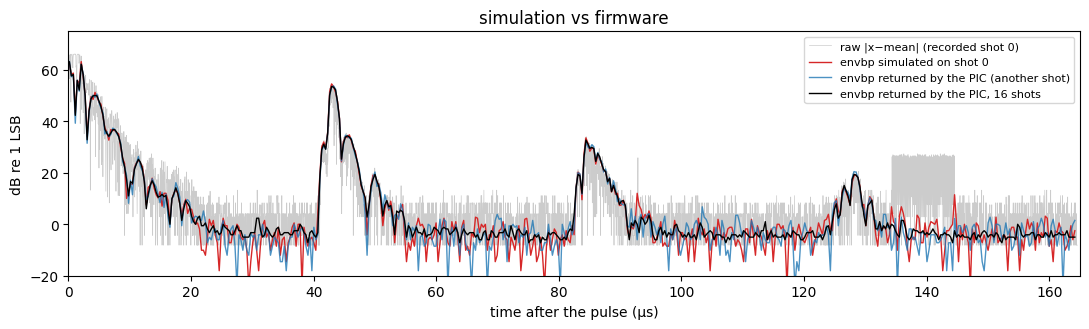

In [7]:
def stats(A, qq=q, ee=e1):
    pk = np.array([a[ee].max() for a in A]); fl = np.array([np.sqrt((a[qq] ** 2).mean()) for a in A])
    return pk.mean(), fl.mean(), np.mean(20 * np.log10(pk / fl))

E16 = pic_envbp_avg(rf, dt)                                  # all 16 recorded shots averaged as on the PIC
rows = [("raw |x−mean| (per sample)", stats(R, qr, e1r)),
        ("env 8, PIC measured, 1 shot (x pi/2)", stats(z["env_s1"] * np.pi / 2)),
        ("envbp 3.3/2.5, simulated, 1 shot", stats(E)),
        ("envbp 3.3/2.5, PIC measured, 1 shot", stats(z["bp_f3300_b2500_s1"])),
        ("envbp 3.3/2.5, simulated, 16 shots", stats([E16])),
        ("envbp 3.3/2.5, PIC measured, 16 shots", stats(z["bp_f3300_b2500_s16"]))]
print(f"{'':42s} {'echo pk':>8s} {'floor rms':>10s} {'pk/floor':>9s}")
for name, (p, fl, d) in rows:
    print(f"{name:42s} {p:8.1f} {fl:10.2f} {d:8.1f} dB")

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(t, db(R[0]), color="0.8", lw=0.5, label="raw |x−mean| (recorded shot 0)")
ax.plot(te, db(E[0]), "C3", lw=1.0, label="envbp simulated on shot 0")
ax.plot(te, db(z["bp_f3300_b2500_s1"][0]), "C0", lw=1.0, alpha=0.8, label="envbp returned by the PIC (another shot)")
ax.plot(te, db(z["bp_f3300_b2500_s16"][0]), "k", lw=1.0, label="envbp returned by the PIC, 16 shots")
ax.set_xlim(0, 165); ax.set_ylim(-20, 75); ax.set_xlabel("time after the pulse (µs)"); ax.set_ylabel("dB re 1 LSB")
ax.legend(fontsize=8, loc="upper right"); ax.set_title("simulation vs firmware"); fig.tight_layout()

## 7 · The other filters recorded on the board (fc / FWHM)

The campaign also ran 3.3 / 1.5, 3.3 / 4.0 and 4.0 / 4.0 MHz. A narrower band lowers the floor further but
lengthens the kernel (σ_t ∝ 1/FWHM), i.e. smears the echo in time (worse axial resolution); a wider band keeps
more noise. Simulated vs measured, 1 shot:

fc / FWHM (kHz)     taps  -6 dB echo width  sim dB  PIC dB
 3300 /  1500         39           1.47 µs    57.9    56.8
 3300 /  2500         23           1.45 µs    56.5    56.0


 3300 /  4000         15           1.45 µs    52.8    54.5
 4000 /  4000         15           1.57 µs    49.9    48.3


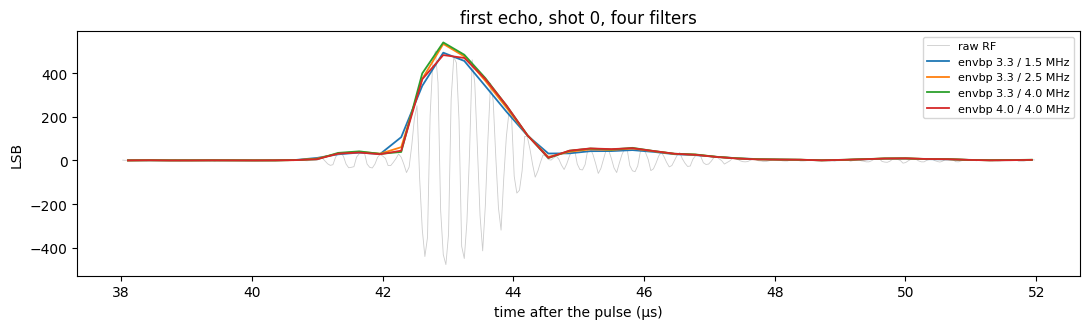

In [8]:
print(f"{'fc / FWHM (kHz)':18s} {'taps':>5s} {'-6 dB echo width':>17s} {'sim dB':>7s} {'PIC dB':>7s}")
fig, ax = plt.subplots(figsize=(11, 3.4))
m = (t >= 38) & (t <= 52)
ax.plot(t[m], x0[m], color="0.8", lw=0.6, label="raw RF")
for fc, bw in ((3300, 1500), (3300, 2500), (3300, 4000), (4000, 4000)):
    Ek = np.array([pic_envbp(y, dt, fc_khz=fc, bw_khz=bw)[0] for y in rf]); hk = pic_envbp(rf[0], dt, fc_khz=fc, bw_khz=bw)[3]
    w6 = np.mean([(a[e1] >= a[e1].max() / 2).sum() * dec * dt * 1e6 for a in Ek])
    print(f"{fc:5d} / {bw:5d}      {2*hk+1:5d} {w6:14.2f} µs {stats(Ek)[2]:7.1f} {stats(z[f'bp_f{fc}_b{bw}_s1'])[2]:7.1f}")
    me = (te >= 38) & (te <= 52)
    ax.plot(te[me], Ek[0][me], lw=1.3, label=f"envbp {fc/1000:.1f} / {bw/1000:.1f} MHz")
ax.set_xlabel("time after the pulse (µs)"); ax.set_ylabel("LSB"); ax.set_title("first echo, shot 0, four filters")
ax.legend(fontsize=8); fig.tight_layout()

## Take-aways

* The Gaussian complex FIR on the PIC (23 taps at 3.3 / 2.5 MHz, evaluated once per 8 samples) is a cheap
  band-pass + Hilbert envelope: the simulation reproduces the firmware's echo / floor figure within ~0.5 dB
  (cell 6), on data recorded with the board.
* It brings the **first-echo / floor from ~44 dB (`env`) to ~56 dB** in a single shot; the envelope's **full dynamic
  range (transmit pulse peak / noise floor) is ≈ 66 dB**. Averaging 16 shots adds only ~1 dB here: the remaining
  floor between the echoes is mostly *in-band, repeatable* signal (reverberation / ring-down), not random noise.
* Re-running: `jupyter nbconvert --to notebook --execute --inplace python/notebooks/05_envbp_filter.ipynb`
  (no board needed). On a board, `dev.envbp(8, shots, 25, 3300, 2500)` returns the firmware's version of the red curve.